# 正则化与过拟合

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

用16阶多项式穿过十几个点，训练误差可能很小，区间边缘却猛烈摆动。最小二乘只看你提供的目标，无法自动知道你更喜欢平滑、简单或物理合理的解释。

## 将偏好写进目标

岭型正则化使用

$$F_\lambda(x)=\frac12\|Ax-y\|^2+\frac\lambda2\|Dx\|^2.$$

$D=I$惩罚参数长度；若不希望惩罚截距，可令$D=\operatorname{diag}(0,1,\ldots,1)$。它等价于一个增广最小二乘问题：

$$\min_x\left\|\begin{bmatrix}A\\\sqrt\lambda D\end{bmatrix}x-
\begin{bmatrix}y\\0\end{bmatrix}\right\|^2.$$

正则化引入偏差，以换取对噪声的较低敏感度。$D$和参数单位很重要：如果单位改变却不调整惩罚，表达的先验也随之改变。

chosen lambda: 0.00043287612810830614 coefficient norms: 3761.5230070368407 6.291813881254787


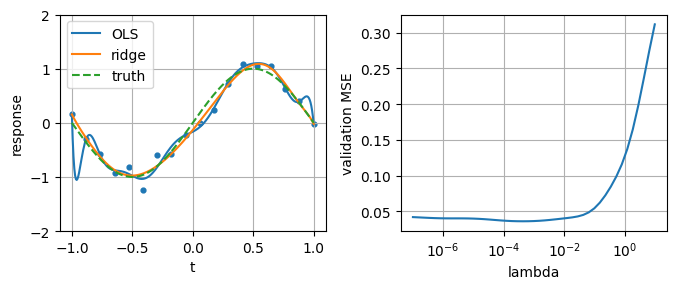

In [2]:
rng = np.random.default_rng(106)
f = lambda t: np.sin(np.pi*t)
t = np.linspace(-1, 1, 18); y = f(t)+rng.normal(0, .18, len(t))
tv = rng.uniform(-1, 1, 70); yv = f(tv)+rng.normal(0, .18, len(tv))
degree = 14
design = lambda t: np.vander(t, degree+1, increasing=True)
A, V = design(t), design(tv)
D = np.diag(np.r_[0., np.ones(degree)])
def ridge(lam):
    return np.linalg.lstsq(np.vstack([A, np.sqrt(lam)*D]),
                          np.r_[y, np.zeros(degree+1)], rcond=None)[0]
lambdas = np.logspace(-7, 1, 45)
validation = np.array([np.mean((V@ridge(l)-yv)**2) for l in lambdas])
best = lambdas[np.argmin(validation)]
plain = np.linalg.lstsq(A, y, rcond=None)[0]; regularized = ridge(best)
grid = np.linspace(-1, 1, 300)
print('chosen lambda:', best, 'coefficient norms:', np.linalg.norm(plain),
      np.linalg.norm(regularized))
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].scatter(t, y, s=12); ax[0].plot(grid, design(grid)@plain, label='OLS')
ax[0].plot(grid, design(grid)@regularized, label='ridge')
ax[0].plot(grid, f(grid), '--', label='truth'); ax[0].set_ylim(-2, 2)
ax[0].set(xlabel='t', ylabel='response'); ax[0].legend()
ax[1].semilogx(lambdas, validation); ax[1].set(xlabel='lambda', ylabel='validation MSE')
plt.tight_layout(); plt.show()

## 怎样选择惩罚强度

上例使用独立验证集选$\lambda$。一旦你根据验证结果挑选参数，它就不再是完全未使用的测试集。最终性能应在第三份独立数据上评估；数据少时可用交叉验证，并将调参与最终评估分开。

在$D=I$时，SVD中的每个方向由$1/\sigma_j$改为$\sigma_j/(\sigma_j^2+\lambda)$。小奇异值方向被压低，这解释了稳定性如何改善。它并不保证所有真参数或所有数据集都得到更小误差。

高斯噪声与高斯先验下，正则化还可解释为最大后验估计。若噪声方差为$\sigma^2$、零均值先验方差为$\tau^2$，在未白化目标的写法下$\lambda=\sigma^2/\tau^2$。要先固定目标的尺度，再比较不同文献里的$\lambda$。

In [3]:
tt = rng.uniform(-1, 1, 200)
yt = f(tt)+rng.normal(0, .18, len(tt))
print('independent test MSE, OLS:', np.mean((design(tt)@plain-yt)**2))
print('independent test MSE, ridge:', np.mean((design(tt)@regularized-yt)**2))
assert np.all(np.isfinite(regularized))

independent test MSE, OLS: 0.06030827732864676
independent test MSE, ridge: 0.03305857997927622


## 练习与解答

练习：令$\lambda\to\infty$，上例的曲线趋向什么？解答：非截距系数被压向零，留下一个近似常数模型；由于截距未受罚，它不必趋向零。

练习：增加一个参数后，带正则化的纯训练残差一定下降吗？解答：若比较的是各自正则化目标的最优解，纯训练残差未必单调；“增加列空间使训练残差不升”针对的是未加额外惩罚的普通最小二乘。

练习：正则化和LM阻尼看起来都增加$\lambda I$，是否相同？解答：正则化改变最终要解的目标；第10章LM阻尼主要限制当前局部迭代步，通常随迭代调整，二者用途不同。